In [2]:
from qiskit_algorithms import Grover
from qiskit.primitives import StatevectorSampler
from qiskit.exceptions import MissingOptionalLibraryError
from qiskit.circuit.library.phase_oracle import PhaseOracleGate
from qiskit.synthesis.boolean.boolean_expression import BooleanExpression
from qiskit_algorithms import AmplificationProblem
from qiskit.visualization import plot_histogram

In [27]:
formula = "(x0 | ~x1 | x3) & (~x0 | x2 | x5) & (x1 | x4 | ~x5) & (~x2 | x3 | x4) & (x0 | ~x4 | x5) & (~x1 | x2 | ~x3) & (x0 | x2 | ~x5) & (~x0 | x3 | x4) & (x1 | ~x2 | x5) & (~x1 | ~x4 | x3) & (x0 | ~x3 | x5) & (~x0 | x1 | ~x4) & (x2 | x3 | ~x4) & (~x2 | ~x3 | x5) & (x1 | x3 | x4) & (~x0 | ~x2 | x4) & (x0 | x1 | ~x5) & (~x1 | x2 | x4)"

In [28]:
resutl = None
try:
    oracle = PhaseOracleGate(formula)
    problem = AmplificationProblem(oracle)
    grover = Grover(sampler=StatevectorSampler())
    result = grover.amplify(problem)
except MissingOptionalLibraryError as ex:
    print(ex)

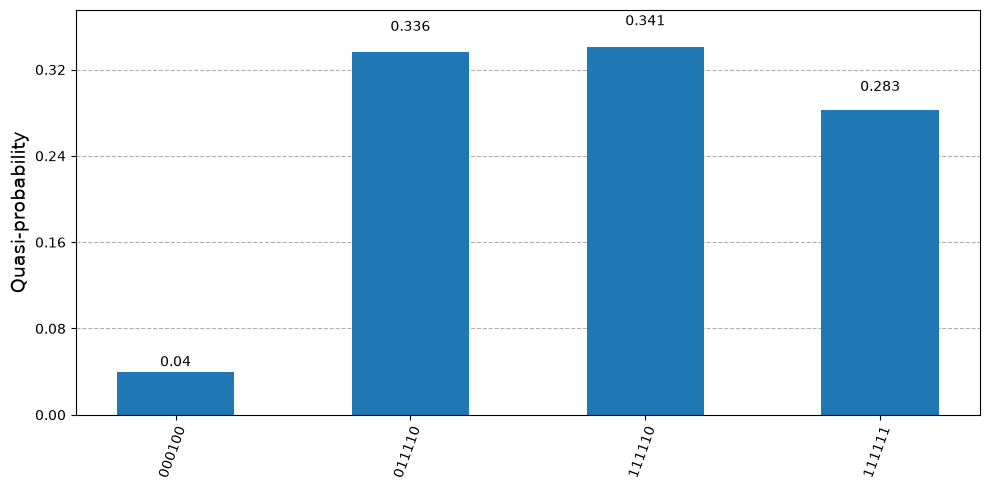

In [29]:
counts = result.circuit_results[0]

# First filter: above initial average
avg1 = sum(counts.values()) / len(counts)
filtered1 = {
    k: v for k, v in counts.items()
    if v > avg1
}

# Second filter: above the new average
avg2 = sum(filtered1.values()) / len(filtered1)
filtered2 = {
    k: v for k, v in filtered1.items()
    if v > avg2
}

display(plot_histogram(filtered1, figsize=(10, 5)))